# Période et raffinement par dérive de phase

Le notebook lit tout le CSV, recherche puis affine une période sur l'apprentissage. Le graphique final utilise toute la série.

| Mode | Données | Méthode |
|---|---|---|
| `events` | Une ligne par événement | Epoch folding, χ² de Pearson |
| `values` | Une valeur par instant | Epoch folding, ANOVA L de Davies |

**CSV événements :**
```csv
timestamp
2025-12-01T00:00:00.123456789Z
2025-12-01T00:00:01.250000000Z
```

**CSV valeurs :**
```csv
timestamp,value
2025-12-01T00:00:00.123456789Z,125.5
2025-12-01T00:00:01.250000000Z,84.0
```

## 1. Paramètres

Renseigner `csv_path`, `mode`, la plage de périodes, `phase_bins`
et l’unité `value_label`.

Dépendances : pandas, NumPy, matplotlib. Exécuter les cellules dans l’ordre.


In [95]:
from math import ceil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = 'timeseries.csv'
mode = 'values' #values/events
p_min, p_max = (1.0, 40.0) #seconds
phase_bins = 50
value_label = 'Lifetime (ms)'
title = Path(csv_path).stem
plt.rcParams['figure.dpi'] = 120
cyan, gold, dark = ('#62e4df', '#f3cf86', '#080b17')

train_fraction = .5
drift_blocks = 4
refine_factor = 10
min_correlation = .5
test_blocks = 3
period_tolerance = .01

## 2. Lecture intégrale du CSV

Toutes les lignes du fichier sont analysées, sans filtre, tri ni nettoyage car la timeseries est supposée nettoyée.
Le premier timestamp définit l’origine ; le dernier définit la fin de la série.

En mode événements, cet intervalle est supposé observé sans interruption. Le fichier
ne permet pas de connaître les périodes silencieuses avant le premier ou après le dernier
événement : elles ne font donc pas partie de l’analyse. La borne numérique de fin est
placée juste après le dernier timestamp pour inclure aussi le dernier événement.


In [96]:
data = pd.read_csv(csv_path)
dates = pd.to_datetime(data.timestamp, format = 'ISO8601', utc = True)
timestamps = pd.DatetimeIndex(dates).as_unit('ns').asi8
elapsed = timestamps-timestamps[0]
times = elapsed/1e9
values = data.value.to_numpy(float) if mode == 'values' else None

### Séparation apprentissage/test
La recherche initiale et le raffinement utilisent uniquement les lignes avant
la frontière. Comme dans le notebook original, la recherche initiale prend
le dernier timestamp d'apprentissage comme fin d'exposition.
Les profils de sous-fenêtres utilisent leurs bornes exactes, y compris les
intervalles silencieux en mode événements.


In [97]:
split = times[-1]*train_fraction
end = np.nextafter(times[-1], np.inf)
train = times < split
train_times = times[train]
train_values = values[train] if values is not None else None
print(f"Learning: {train.sum():,} rows | Test: {(~train).sum():,} rows")

Learning: 308 rows | Test: 286 rows


## 3. Recherche initiale sur l’apprentissage

Les données sont repliées sur chaque période candidate. Le code maximise :

- **Événements** : $\sum_j (n_j-e_j)^2/e_j$, où $e_j$ tient compte du temps
  d’exposition de chaque phase, y compris les cycles partiels aux bords.
- **Valeurs** : $L=[SSA/(K-1)]/[SSE/(N-K)]$, avec $K$ classes occupées,
  $N$ mesures, $SSA$ la dispersion entre classes et $SSE$ la dispersion résiduelle.

La grille est régulière en fréquence, avec un pas au plus égal à $1/(4MT)$
($M$ classes, durée $T$). Le calcul est effectué par lots pour limiter la mémoire.
Au moins cinq cycles sont requis.

La période retenue est une candidate : les alias et harmoniques restent possibles.
Aucune significativité n’est attribuée automatiquement.

Références : [Leahy et al., 1983](https://adsabs.harvard.edu/pdf/1983ApJ...272..256L)
et [Davies, 1990](https://adsabs.harvard.edu/pdf/1990MNRAS.244...93D).


In [98]:
def phase_labels(times, periods, bins):
  """assign each observation to a phase bin"""
  phase = np.remainder(times, periods)/periods
  labels = (phase*bins).astype(int)
  
  return np.minimum(labels, bins-1)

def phase_exposure(periods, span, bins):
  """compute exposure for each phase over the full file"""
  periods = np.asarray(periods).reshape(-1, 1)
  cycles = np.floor(span/periods)
  remaining = span-cycles*periods
  phase_start = np.arange(bins)*(periods/bins)
  partial_exposure = np.clip(remaining-phase_start, 0, (periods/bins))
  
  return cycles*(periods/bins) + partial_exposure

def period_scores(times, values, periods, bins, span):
  """compute pearson or davies scores for a batch of periods"""
  labels = phase_labels(times, periods[:, None], bins)
  offsets = np.arange(len(periods))[:, None]*bins
  groups = labels + offsets
  
  flat_groups = groups.ravel()
  counts = np.bincount(flat_groups, minlength = len(periods)*bins)
  counts = counts.reshape(len(periods), bins)
  
  if values is None:
    exposure = phase_exposure(periods, span, bins)
    expected = (len(times)/span)*exposure #event_rate*exposure
    deviation = counts - expected
    contributions = deviation**2/expected
    return contributions.sum(axis = 1)
  
  centered = values-values.mean()
  repeated = np.tile(centered, len(periods))
  totals = np.bincount(flat_groups, weights = repeated,
    minlength = len(periods)*bins).reshape(len(periods), bins)
  
  means = totals/np.maximum(counts, 1)
  fitted = means.ravel()[groups]
  
  residual = centered-fitted
  
  between = np.sum(counts*means**2, axis = 1)
  within = np.sum(residual**2, axis = 1)
  occupied = (counts > 0).sum(axis = 1)
  between_df = occupied-1
  within_df = len(times)-occupied
  
  with np.errstate(divide = 'ignore', invalid = 'ignore'):
    between_variance = between/between_df
    within_variance = within/within_df
    scores = between_variance/within_variance
  invalid = (between_df <= 0) | (within_df <= 0)
  scores[invalid] = np.nan
  
  return scores

def find_period(times, values, p_min, p_max, bins):
  """select the best period on a uniform frequency grid"""
  span = np.nextafter(times[-1], np.inf)
  p_max = min(p_max, span/5)

  trials = ceil(((1/p_min) - (1/p_max))*(4*bins*span))+1 #ceil(freq_range*grid_density)+1
  frequencies = np.linspace(1/p_min, 1/p_max, trials)
  periods = 1/frequencies
  scores = np.full(trials, np.nan)
  batch = max(1, 262_144//len(times))
  
  for start in range(0, trials, batch):
    stop = min(start+batch, trials)
    candidates = periods[start:stop]
    scores[start:stop] = period_scores(times, values, candidates, bins, span)
    
  if np.isnan(scores).all(): raise ValueError('No identifiable period.')
  best = np.nanargmax(scores)
  return float(periods[best])

initial_period = find_period(train_times, train_values,
  p_min, p_max, phase_bins)
print(f"Initial period: {initial_period:.9f} s")

Initial period: 29.953564745 s


## 4. Mesurer la dérive et raffiner localement
### Paramètres du raffinement
La fraction porte sur la durée. Les observations simultanées restent ensemble.
Les quatre sous-fenêtres servent uniquement à estimer la dérive dans
l'apprentissage. Les trois blocs de test restent indépendants.
`phase_bins` règle la résolution des profils de corrélation et du graphique. Le raffinement local est au moins `refine_factor` fois plus fin que
la grille initiale. `min_correlation` est un seuil pratique de ressemblance,
pas un seuil de significativité.

### Processus
Chaque sous-fenêtre est repliée avec la même origine de phase. 
La corrélation circulaire compare son profil au premier : seules les phases observées 
dans les deux profils participent au calcul. Les moyennes sont centrées et normalisées,
ce qui permet des changements de niveau et d'amplitude positive.

Chaque corrélation exige au moins `max(4, phase_bins//2)` phases communes.

En mode valeurs, si ces moyennes sont trop peu couvertes ou trop peu corrélées,
le calcul suit plutôt les **groupes de valeurs** : les quartiles de l'apprentissage
définissent jusqu'à quatre groupes. Pour chacun, on construit une distribution
de phase normalisée dans chaque sous-fenêtre. La corrélation décale toutes ces
distributions ensemble. 

Ce repli suit le calendrier des groupes de valeurs, pas seulement leurs moyennes ;
un changement de leur distribution ou de l'échantillonnage peut donc l'affecter.
Une parabole autour du maximum donne un décalage inférieur à un bin ;
`unwrap` déroule les passages par la phase zéro.
Une régression des décalages sur le temps donne une pente `slope`, en
cycles/seconde. 
La correction proposée est :
$P_{\mathrm{corr}}=\frac{1}{1/P_0-b}.$

Une pente positive oriente donc la recherche vers les périodes plus longues.
La recherche locale couvre la période initiale, la correction et une marge
des deux côtés. Elle reste dans les bornes initiales et n'utilise jamais le test.
Elle retient la plus petite dispersion des décalages entre sous-fenêtres ;
le score initial départage les égalités.
La méthode ne garantit ni la vraie période ni une précision supérieure aux données.

In [99]:
def block_profiles(times, values, period, bins, edges, grouped = False):
  """fold each training block with a common phase origin"""
  profiles = []
  if grouped:
    cuts = np.unique(np.quantile(values, [.25, .5, .75]))
    groups = np.searchsorted(cuts, values)
    
  labels = phase_labels(times, period, bins)
  for start, stop in zip(edges[:-1], edges[1:]):
    mask = (times >= start) & (times < stop)
    counts = np.bincount(labels[mask], minlength = bins)
    if grouped:
      cells = groups[mask]*bins+labels[mask]
      counts = np.bincount(cells, minlength = (len(cuts)+1)*bins)
      counts = counts.reshape(-1, bins)
      profile = counts/np.maximum(counts.sum(axis = 1, keepdims = True), 1)
      if mask.sum() < 3 or np.ptp(values) == 0: profile[:] = np.nan
      profiles.append(profile)
      continue
    if values is None:
      weights = phase_exposure([period], stop, bins)[0]
      weights -= phase_exposure([period], start, bins)[0]
      totals = counts
    else:
      weights = counts
      totals = np.bincount(labels[mask], weights = values[mask],
        minlength = bins)
    profile = totals/np.where(weights > 0, weights, np.nan)
    if mask.sum() < 3: profile[:] = np.nan
    profiles.append(profile)
  return np.array(profiles)

def phase_shift(reference, profile):
  """estimate a circular shift from overlapping phase bins"""
  bins = reference.shape[-1]
  scores = np.full(bins, np.nan)
  
  for shift in range(bins):
    moved = np.roll(reference, shift, axis = -1)
    keep = np.isfinite(moved) & np.isfinite(profile)
    if keep.sum() < max(4, bins//2): continue
    left, right = moved[keep], profile[keep]
    left, right = left-left.mean(), right-right.mean()
    scale = np.linalg.norm(left)*np.linalg.norm(right)
    if scale > 0: scores[shift] = np.dot(left, right)/scale
  
  if not np.isfinite(scores).any(): return np.nan, np.nan
  
  peak = int(np.nanargmax(scores))
  before, best, after = scores[(peak-1)%bins], scores[peak], scores[(peak+1)%bins]
  curve = before-2*best+after
  offset = 0.
  if np.isfinite(curve) and curve < 0:
    offset = np.clip(.5*(before-after)/curve, -.5, .5)
  return (peak+offset)/bins, best

def phase_drift(times, values, period, bins, edges, grouped = False):
  """measure phase slope and dispersion across training blocks"""
  profiles = block_profiles(times, values, period, bins, edges, grouped)
  pairs = [phase_shift(profiles[0], profile) for profile in profiles]
  shifts, correlations = np.array(pairs).T
  centers = (edges[:-1]+edges[1:])/2
  
  if not np.isfinite(shifts).all():
    return np.nan, np.nan, np.nan, np.nan
  
  shifts = np.unwrap(2*np.pi*shifts)/(2*np.pi)
  slope, intercept = np.polyfit(centers, shifts, 1)
  residual = shifts-(slope*centers+intercept)
  scatter = np.std(shifts)
  error = np.sqrt(np.mean(residual**2))
  return slope, scatter, error, correlations.min()

def refine_period(times, values, period, bins, span, blocks,
  p_min, p_max, search_bins, factor, min_correlation):
  """return the period with the best training phase coherence"""
  edges = np.linspace(0, span, blocks+1)
  slope, scatter, error, correlation = phase_drift(times, values, period, bins, edges)
  grouped = values is not None and (not np.isfinite(slope) or correlation < min_correlation)
  
  if grouped: 
    slope, scatter, error, correlation = phase_drift(times, values, period, bins, edges, grouped)
  
  if not np.isfinite(slope) or correlation < min_correlation: return period
  
  step = 1/(4*search_bins*np.nextafter(times[-1], np.inf))
  margin = max(abs(slope)/4, 1/(bins*span), 2*step)
  low = max(1/min(p_max, times[-1]/5), min(1/period, 1/period-slope)-margin)
  high = min(1/p_min, max(1/period, 1/period-slope)+margin)
  
  if not low <= 1/period-slope <= high: return period
  
  trials = max(101, ceil((high-low)*factor/step)+1)
  candidates = 1/np.linspace(low, high, trials)
  candidates = np.unique(np.r_[candidates, period, period-slope])
  best, rank = period, (scatter, -np.inf)
  
  for candidate in candidates:
    _, scatter, error, correlation = phase_drift(
      times, values, candidate, bins, edges, grouped)
    if not (correlation >= min_correlation and error <= 1/bins
      and scatter <= rank[0]): continue
    score = period_scores(times, values, np.array([candidate]),
      search_bins, np.nextafter(times[-1], np.inf))[0]
    if not np.isnan(score) and (scatter, -score) < rank:
      best, rank = float(candidate), (scatter, -score)
      
  return best

period_s = refine_period(
  train_times, train_values, initial_period, phase_bins, split,
  drift_blocks, p_min, p_max, phase_bins, refine_factor, min_correlation)
print(f"Initial: {initial_period:.9f} s | Refined: {period_s:.9f} s")

Initial: 29.953564745 s | Refined: 29.997177061 s


### Vérification indépendante sur le reste
Chaque bloc de test est analysé séparément avec la grille initiale.
L'écart à la période affinée est affiché en pourcentage. La tolérance de 1 %
est pratique et réglable ; ce n'est pas un intervalle de confiance.
Ces résultats ne modifient pas la période utilisée pour le graphique.


In [100]:
rows = []
edges = np.linspace(split, end, test_blocks+1)
for index, (start, stop) in enumerate(zip(edges[:-1], edges[1:]), 1):
  mask = (times >= start) & (times < stop)
  estimate, change = np.nan, np.nan
  status = 'indeterminate'
  try:
    if mask.sum() < 3 or period_s > (stop-start)/5:
      raise ValueError('Too few observations or cycles.')
    block_times = times[mask]-start
    if p_min > min(p_max, block_times[-1]/5):
      raise ValueError('Search bounds exceed the block duration.')
    block_values = values[mask] if values is not None else None
    estimate = find_period(block_times, block_values,
      p_min, p_max, phase_bins)
    change = (estimate-period_s)/period_s
    status = 'within tolerance' if abs(change) <= period_tolerance else (
      'different')
    reason = ''
  except ValueError as error:
    reason = str(error)
  rows.append({'block': index, 'period_s': estimate,
    'difference_pct': 100*change, 'status': status, 'reason': reason})
display(pd.DataFrame(rows))

,block,period_s,difference_pct,status,reason
0,1,3.337020,-88.875555,different,
1,2,30.022827,0.085508,within tolerance,
2,3,30.030735,0.111871,within tolerance,


## 4. Repliement

En mode événements, le profil représente un taux par seconde d’exposition.
En mode valeurs, il représente la moyenne des mesures par phase.
Les cases sans mesure restent manquantes ; les cases observées sans événement valent zéro.


In [101]:
def fold_series(times, values, period, bins):
  """build the profile and cycle matrix with their weights"""
  span = np.nextafter(times[-1], np.inf)
  cycles = np.floor(times/period).astype(int)
  phases = phase_labels(times, period, bins)
  rows = cycles.max()+1
  cell_count = rows*bins
  
  if cell_count > 2_000_000: raise MemoryError('Reduce the heatmap size.')
  counts = np.bincount(cycles*bins+phases, minlength = cell_count).reshape(rows, bins)
  
  if values is None:
    totals = counts
    cycle_start = np.arange(rows)[:, None]*period
    phase_start = np.arange(bins)*period/bins
    weights = np.clip(span-cycle_start-phase_start, 0, period/bins)
  else:
    totals = np.bincount(cycles*bins+phases, weights = values, minlength = cell_count)
    totals = totals.reshape(rows, bins)
    weights = counts
  
  matrix = totals/np.where(weights > 0, weights, np.nan)
  phase_totals = totals.sum(axis = 0)
  phase_weights = weights.sum(axis = 0)
  profile = phase_totals/np.where(phase_weights > 0, phase_weights, np.nan)
  
  return profile, matrix, weights

profile, matrix, weights = fold_series(times, values, period_s, phase_bins)
feature = 'Events / second' if mode == 'events' else value_label

## 5. Graphique

La courbe montre le profil moyen sans lissage. La heatmap conserve les cycles manquants
en gris et utilise une échelle logarithmique de couleur, signée si nécessaire.
Pour l’affichage, les cycles contigus sont regroupés en au plus 250 lignes, pondérées
par l’exposition ou le nombre de mesures. La période apparaît dans le titre.


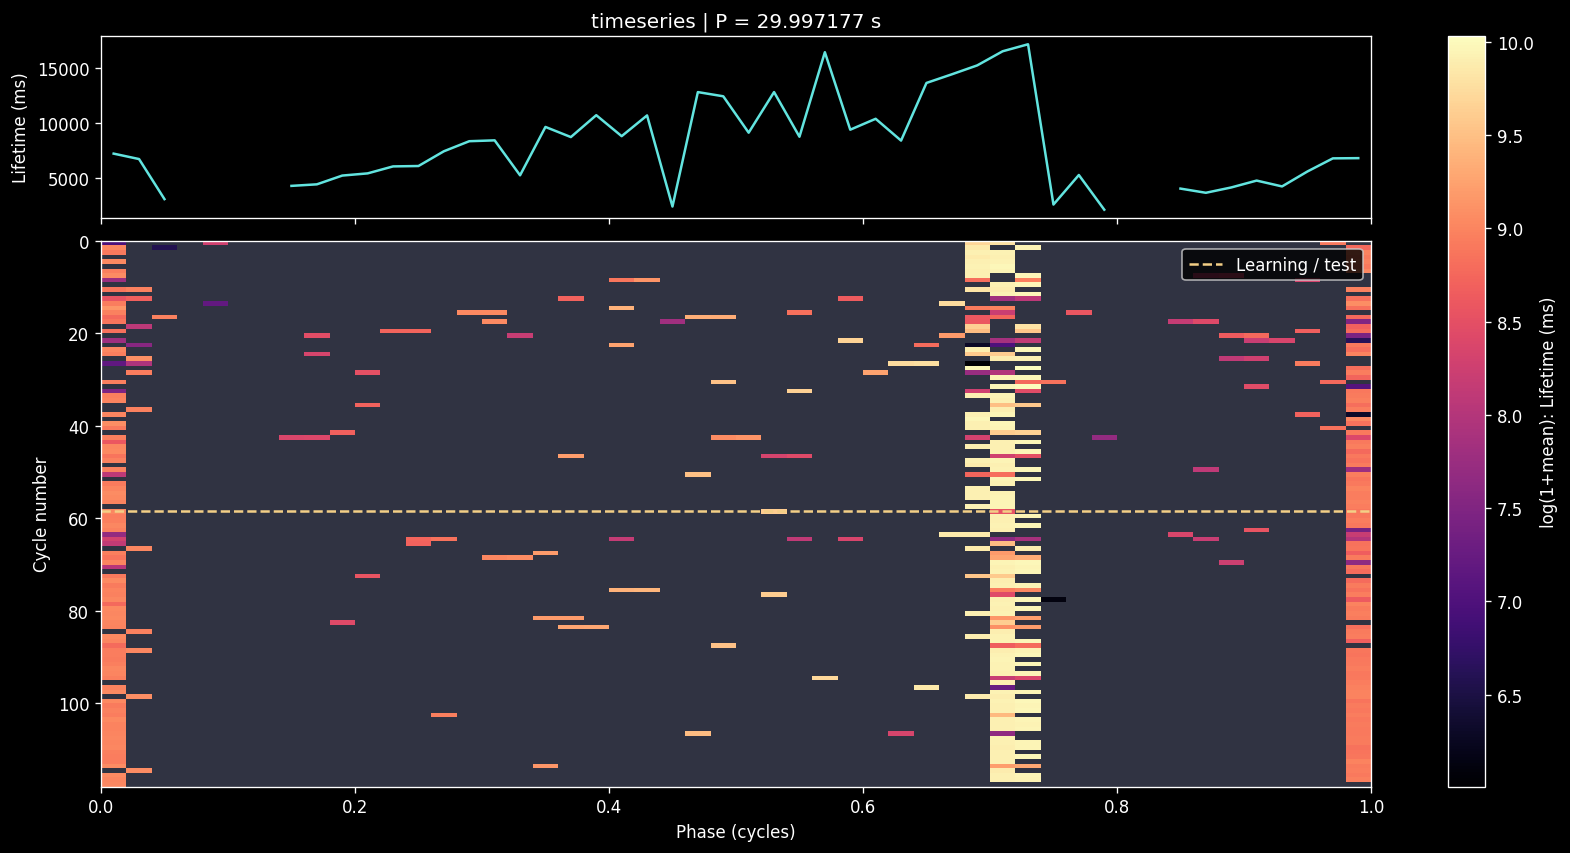

In [102]:
rows, bins = matrix.shape
edges = np.linspace(0, rows, min(250, rows)+1, dtype = int)
split_cycle = split/period_s
border = [int(np.floor(split_cycle)), int(np.ceil(split_cycle))]
edges = np.unique(np.r_[edges, np.clip(border, 0, rows)])
totals = np.nan_to_num(matrix)*weights
totals = np.add.reduceat(totals, edges[:-1], axis = 0)
counts = np.add.reduceat(weights, edges[:-1], axis = 0)
means = totals/np.where(counts > 0, counts, np.nan)

colors = np.sign(means)*np.log1p(np.abs(means))
phases = np.linspace(0, 1, bins+1)
centers = (phases[:-1]+phases[1:])/2
cmap = plt.get_cmap('magma').with_extremes(bad = '#303342')

with plt.style.context('dark_background'):
  fig, (top, bottom) = plt.subplots(2, 1, figsize = (13, 7),
    sharex = True, height_ratios = [1, 3], constrained_layout = True)
  top.plot(centers, profile, color = cyan)
  top.set(ylabel = feature, title = f"{title} | P = {period_s:.6f} s")

  mesh = bottom.pcolormesh(phases, edges, colors, cmap = cmap)
  bottom.axhline(split_cycle, color = gold, linestyle = '--',
    label = 'Learning / test')
  bottom.legend(loc = 'upper right')
  bottom.invert_yaxis()
  bottom.set(xlabel = 'Phase (cycles)', ylabel = 'Cycle number', xlim = (0, 1))
  fig.colorbar(mesh, ax = [top, bottom], label = f"{'signed log(1+|mean|)' if np.any(means < 0) else 'log(1+mean)'}: {feature}")
  plt.show()